# Laboratorio 9. Series de tiempo y forecasting

## Notebook 4. Modelos de librería

Este notebook cubre los modelos de la sección 5 que vienen de librerías. Los baselines estadísticos usan StatsForecast, el modelo de árboles usa MLForecast con LightGBM, las redes de la sección 5 (N-HiTS, TCN, PatchTST, iTransformer y DeepAR) usan NeuralForecast y el modelo fundacional es Chronos-Bolt. También trae las iteraciones de la sección 5.2 que le tocan a estos modelos (la historia de entrenamiento y la ventana L de PatchTST), el reentrenamiento mensual, las tres semillas del mejor modelo de deep learning y el pronóstico probabilístico.

Todas las corridas están en `src/experimentos_libreria.py` y quedan guardadas en `Resultados/`. Si ya existen, el notebook solo las carga. Todos los modelos pasan por la misma función `backtest` del notebook 3, con los mismos 92 orígenes de prueba, y los pesos se entrenan una sola vez con datos hasta el 2014-09-30 (entrenamiento hasta el 2014-06-30 y validación de julio a septiembre para el early stopping). Los modelos se entrenaron en una PC con GPU NVIDIA GeForce RTX 4060 Ti de 8 GB, menos los baselines estadísticos y LightGBM que usan el CPU (Intel Core i5-12400).

In [1]:
import sys
import warnings
import json
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore", message="The 'generic' unit for NumPy timedelta")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config as C
from src.backtest import ORIGENES_VAL
from src.registro import cargar_iteracion, cargar_metricas
from src.graficas import AZUL, NARANJA, VERDE, GRIS, GRIS_CLARO, CUALITATIVA, estilo, etiquetas_finales, guardar, pie

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
R = C.RESULTADOS
PRUEBA_ORIGENES = pd.date_range(C.INICIO_TEST, "2014-12-31", freq="D")


def metricas(nombres):
    filas = []
    for n in nombres:
        m = cargar_metricas(n)
        filas.append({"Modelo": n, "L": m["L"], "MAE val": None, "MASE val": m.get("MASE_val"),
                      "MAE": m["MAE"], "RMSE": m["RMSE"], "WAPE": m["WAPE"], "MASE": m["MASE"],
                      "MASE Navidad": m["MASE_navidad"], "Entrenamiento (s)": m["t_entrenamiento_s"],
                      "Inferencia (s)": m["t_inferencia_s"], "Hardware": m["hardware"]})
    return pd.DataFrame(filas).drop(columns="MAE val")

### 5. Baselines con StatsForecast

Son cuatro modelos sin red neuronal. Sirven como piso, porque cualquier modelo más complejo tiene que ganarles para justificar su costo.

| Modelo | Qué hace |
| --- | --- |
| Naive | Repite la última hora conocida (las 23:00 del día anterior) durante las 24 horas. |
| Seasonal naive 24 h | Repite el día anterior hora por hora. Es la referencia con la que se calcula el MASE. |
| Seasonal naive 168 h | Repite la misma hora de la semana anterior, o sea el mismo día de la semana. |
| MSTL | Separa la serie en tendencia, un ciclo diario, un ciclo semanal (`season_length=[24, 168]`) y resto. Pronostica la tendencia con un AutoETS sin estacionalidad y repite los ciclos. Se reajusta en cada origen con las últimas 8 semanas. |

Los tres primeros no tienen parámetros que entrenar. Se corren una sola vez con `cross_validation(h=24, step_size=24, n_windows=92)` y `backtest` toma el pedazo de cada origen. Antes de pasar los resultados por `backtest` se revisa que los cortes sean las 23:00 del día anterior a cada origen. MSTL se reajusta en cada una de las 92 ventanas, porque con `refit=False` usaría un ajuste viejo y no la historia nueva, y por eso su tiempo se cuenta como tiempo de inferencia.

In [2]:
bl = metricas(["Naive", "SeasonalNaive24", "SeasonalNaive168", "MSTL"])
bl.round(4)

,Modelo,L,MASE val,MAE,RMSE,WAPE,MASE,MASE Navidad,Entrenamiento (s),Inferencia (s),Hardware
0,Naive,1,5.0050,189.4390,561.9161,0.3357,4.3000,4.2145,0.0,0.3636,Intel Core i5-12400 (CPU)
1,SeasonalNaive24,24,0.9662,47.4911,237.6884,0.0842,1.0337,2.2180,0.0,0.3636,Intel Core i5-12400 (CPU)
2,SeasonalNaive168,168,1.1521,43.9846,189.1403,0.0779,1.1113,1.6244,0.0,0.3636,Intel Core i5-12400 (CPU)
3,MSTL,1344,0.9013,39.7577,194.0327,0.0704,0.9228,2.0398,0.0,503.0728,Intel Core i5-12400 (CPU)


El mejor baseline fue MSTL, con MASE de 0.9013 en validación y 0.9228 en prueba, o sea 10.7% mejor que el seasonal naive de 24 horas (1.0337 en prueba). Separar el ciclo diario y el semanal ayuda porque el día anterior trae el ruido de ese día, y MSTL lo promedia sobre 8 semanas. El precio es el tiempo, ya que MSTL tardó 503 segundos en los 92 orígenes y un seasonal naive tarda menos de medio segundo.

El seasonal naive de 168 horas salió peor que el de 24, con 1.1113 contra 1.0337 en prueba y 1.1521 contra 0.9662 en validación. Para un cliente de este panel el día anterior se parece más a hoy que la misma hora de la semana pasada. En la semana de Navidad pasa lo contrario, y el de 168 horas fue el mejor baseline con MASE de 1.62 contra 2.04 de MSTL y 2.22 del seasonal naive de 24. El naive simple, que repite la última hora, quedó en 4.30. A las 23:00 el consumo es el 81% del promedio del día y de las 11:00 a las 21:00 pasa del 120%, entonces repetir esa hora durante 24 horas no sigue el ciclo del día.

Los tres modelos sin parámetros (naive y los dos seasonal naive) se calcularon en una sola llamada a `cross_validation`, entonces comparten el mismo tiempo de inferencia de 0.36 segundos.

### 5. LightGBM global con MLForecast

Un solo modelo para los 100 clientes. Predice la hora siguiente y se aplica de forma recursiva 24 veces, usando cada predicción como rezago de la siguiente. Las entradas son los rezagos 1 a 24 y 168 de la serie (normalizada con el z-score de entrenamiento de cada cliente) y las 7 covariables de calendario del paso que se pronostica. La pérdida es L1 (el error absoluto, igual que en los modelos propios), con 63 hojas por árbol, tasa de aprendizaje de 0.05 y hasta 2,000 árboles con early stopping en el bloque de validación. Se entrena con los datos hasta el 2014-06-30, o sea 2.17 millones de filas.

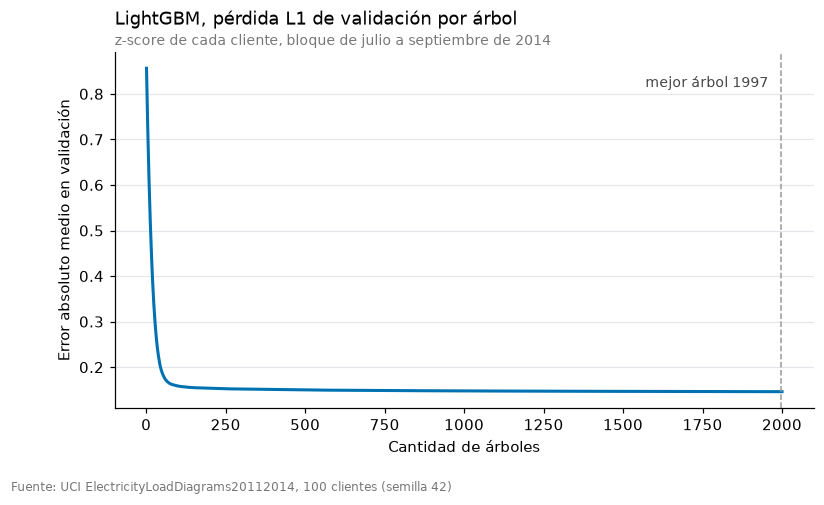

árboles en el mejor punto 1997  tiempo de entrenamiento 99 s  hojas totales 125811


,Modelo,L,MASE val,MAE,RMSE,WAPE,MASE,MASE Navidad,Entrenamiento (s),Inferencia (s),Hardware
0,LightGBM,168,0.8665,38.2738,173.7129,0.0678,0.867,1.6085,99.1938,127.3061,Intel Core i5-12400 (CPU)


In [3]:
it = cargar_iteracion("lgbm_base")
curva = np.array(it["curva_val"])
fig, ax = plt.subplots(figsize=(8.2, 4.2))
estilo(ax, "LightGBM, pérdida L1 de validación por árbol", "z-score de cada cliente, bloque de julio a septiembre de 2014",
       "Cantidad de árboles", "Error absoluto medio en validación")
ax.plot(np.arange(1, len(curva) + 1), curva, color=AZUL, lw=2)
ax.axvline(it["mejor_arbol"], color=GRIS, ls="--", lw=1)
ax.text(it["mejor_arbol"] * 0.98, curva.max() * 0.98, f"mejor árbol {it['mejor_arbol']}", ha="right", va="top", fontsize=9, color="#444444")
pie(fig)
guardar(fig, "4_lightgbm_curva")
plt.show()
print("árboles en el mejor punto", it["mejor_arbol"], " tiempo de entrenamiento", round(it["t_entrenamiento_s"]), "s  hojas totales", it["params_total"])
metricas(["LightGBM"]).round(4)

LightGBM llegó a 0.8670 de MASE en prueba y 0.8665 en validación. Es 16.1% mejor que el seasonal naive de 24 horas y 6.0% mejor que MSTL, entonces aprender de los rezagos y del calendario de los 100 clientes juntos sí paga frente a la descomposición estadística de cada cliente. Entrenó en 99 segundos en el CPU y su modelo final tiene 125,811 hojas.

El mejor árbol fue el 1,997 de los 2,000 permitidos, o sea que el early stopping no llegó a detener el entrenamiento. La pérdida de validación bajó solo 0.4% entre el árbol 1,500 y el 2,000, entonces con más árboles el MASE podría bajar un poco. No se probó. La inferencia tardó 127 segundos porque el modelo es recursivo, o sea que para cada origen predice una hora, la usa como rezago y repite 24 veces.

Con menos historia empeora. Con 3 meses el MASE de validación fue 0.9053, con 12 meses fue 0.8763 y con 30 meses fue 0.8665.

### 5. Modelos de NeuralForecast

Los cinco modelos usan una ventana de entrada `L = 168` horas y un horizonte `h = 24`, la serie normalizada con el z-score de entrenamiento de cada cliente (se normaliza antes de pasar los datos a la librería, así no entra ningún estadístico de validación ni de prueba) y pérdida MAE. Se entrenan con `fit` usando `val_size = 2208`, que son los 92 días de validación, y paran con early stopping sobre ese bloque (revisan cada 100 pasos y esperan 5 revisiones sin mejora). Después se pronostica origen por origen con `predict`, y `backtest` le da a cada origen solo la historia anterior.

| Modelo | Familia | Covariables de calendario | Pasos máximos |
| --- | --- | --- | --- |
| N-HiTS | Residuales | Sí, en `futr_exog_list` | 3000 |
| TCN | Convolucionales | Sí | 3000 |
| PatchTST | Atención | No, NeuralForecast no acepta covariables futuras en este modelo | 3000 |
| iTransformer | Atención | Sí | 3000 |
| DeepAR | Probabilístico | Sí | 1500 |

Se eligió iTransformer entre TFT e iTransformer. TFT necesitó casi 10 GB de memoria RAM solo en los primeros 100 pasos con las 218 mil ventanas de validación, y la GPU de 8 GB no alcanzaba para su configuración por defecto. iTransformer trata cada cliente como una variable y aplica la atención entre clientes, entonces su costo no crece con el número de ventanas.

In [4]:
def tabla_iteraciones(prefijo="nf_"):
    filas = []
    for ruta in sorted((R / "iteraciones").glob(f"{prefijo}*.json")):
        d = json.loads(ruta.read_text())
        ct, cv = np.array(d["curva_train"]), np.array(d["curva_val"])
        c = d["config"]
        filas.append({"id": d["id"], "modelo": c["modelo"], "L": c["L"], "meses": c["meses"],
                      "parámetros": d["params_total"], "pasos": d["pasos_entrenados"],
                      "t entren. (s)": round(d["t_entrenamiento_s"], 1), "memoria GPU (MB)": round(d["memoria_pico_mb"]),
                      "pérdida train final": round(float(ct[-50:, 1].mean()), 4),
                      "pérdida val mínima": round(float(cv[:, 1].min()), 4),
                      "MAE val (kWh)": round(d["MAE_val"], 2), "MASE val": round(d["MASE_val"], 4),
                      "inferencia val (s)": round(d["t_inferencia_s"], 1)})
    return pd.DataFrame(filas)


it_nf = tabla_iteraciones()
it_nf

,id,modelo,L,meses,parámetros,pasos,t entren. (s),memoria GPU (MB),pérdida train final,pérdida val mínima,MAE val (kWh),MASE val,inferencia val (s)
0,nf_DeepAR,DeepAR,168,30,203142,699,53.1,3135,-0.4759,0.8786,300.93,6.2762,36.4
1,nf_DeepAR_n24,DeepAR,168,30,203013,1499,118.6,3553,-0.0287,0.2659,47.06,1.1090,35.2
2,nf_DeepAR_t24,DeepAR,168,30,203142,1499,121.7,3553,-0.0982,0.2781,49.23,1.1598,36.4
3,nf_iTransformer,iTransformer,168,30,6503448,2199,910.6,4577,0.1786,0.1803,34.03,0.8001,27.9
4,nf_NHITS,NHITS,168,30,4193826,2999,140.5,4764,0.1747,0.1820,33.58,0.7877,26.0
5,nf_PatchTST,PatchTST,168,30,466843,2999,271.1,1728,0.2178,0.1991,36.27,0.8484,23.1
6,nf_PatchTST_hist12,PatchTST,336,12,534043,2199,373.5,2372,0.2183,0.1973,36.96,0.8630,25.9
7,nf_PatchTST_hist3,PatchTST,336,3,534043,2299,380.4,1796,0.2174,0.1974,36.35,0.8583,25.1
8,nf_PatchTST_L336,PatchTST,336,30,534043,2999,529.5,3536,0.2123,0.1955,35.77,0.8434,24.4
9,nf_PatchTST_L48,PatchTST,48,30,418843,2999,86.6,586,0.2445,0.2235,39.74,0.9187,20.8


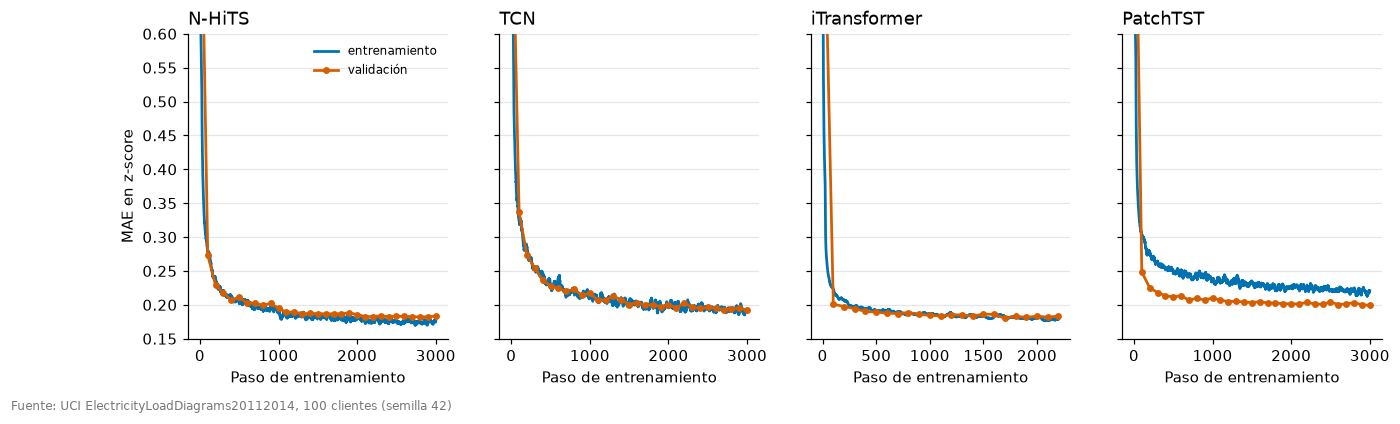

In [5]:
modelos = [("nf_NHITS", "N-HiTS"), ("nf_TCN", "TCN"), ("nf_iTransformer", "iTransformer"), ("nf_PatchTST", "PatchTST")]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
for ax, (id_it, nombre) in zip(axes, modelos):
    d = cargar_iteracion(id_it)
    ct, cv = np.array(d["curva_train"]), np.array(d["curva_val"])
    suave = pd.Series(ct[:, 1]).rolling(25, min_periods=1).mean()
    estilo(ax, nombre, None, "Paso de entrenamiento", "MAE en z-score" if nombre == "N-HiTS" else None)
    ax.plot(ct[:, 0], suave, color=AZUL, lw=1.8, label="entrenamiento")
    ax.plot(cv[:, 0], cv[:, 1], color=NARANJA, lw=1.8, marker="o", ms=3.5, label="validación")
    ax.set_ylim(0.15, 0.6)
axes[0].legend(frameon=False, fontsize=8)
pie(fig)
guardar(fig, "4_curvas_nf")
plt.show()

En validación el mejor modelo de NeuralForecast fue N-HiTS, con MASE de 0.7877, y en prueba quedó en 0.7844. Tiene 4.19 millones de parámetros y entrenó en 141 segundos. iTransformer tuvo el mejor MASE de prueba de los cuatro (0.7810), pero en validación fue peor (0.8001), y como la selección se hace con validación se tomó a N-HiTS como el mejor modelo de deep learning de librería. iTransformer también es mucho más caro, con 6.50 millones de parámetros y 911 segundos de entrenamiento. TCN llegó a 0.8351 en prueba con apenas 155 mil parámetros, y PatchTST a 0.8764 con la mejor ventana (L = 336).

Hay una limitación importante. N-HiTS, TCN y PatchTST usaron los 3,000 pasos permitidos sin que el early stopping los detuviera, y su mejor punto de validación cayó entre los pasos 2,600 y 3,000. La pérdida de validación seguía bajando al llegar al límite, entonces con más pasos estos tres modelos probablemente habrían mejorado. En las curvas la pérdida de entrenamiento y la de validación están muy juntas (0.175 contra 0.182 en N-HiTS), o sea que no hay sobreajuste y a los modelos les faltó entrenamiento.

PatchTST es el único que no usa el calendario. NeuralForecast no acepta covariables futuras en ese modelo.

### 5.2 Iteraciones de PatchTST, ventana L y meses de historia

A PatchTST se le probaron tres ventanas L (48, 168 y 336 horas) y tres cantidades de meses de historia (3, 12 y 30). La ventana se eligió con el MASE de validación, y con esa ventana se probó la historia. Los meses de historia siempre terminan el 2014-06-30, entonces el bloque de validación es el mismo para todas las corridas. Con 3 meses el entrenamiento tiene 2,160 horas por cliente y con 30 meses tiene 21,888.

In [6]:
pt = tabla_iteraciones("nf_PatchTST")
pt

,id,modelo,L,meses,parámetros,pasos,t entren. (s),memoria GPU (MB),pérdida train final,pérdida val mínima,MAE val (kWh),MASE val,inferencia val (s)
0,nf_PatchTST,PatchTST,168,30,466843,2999,271.1,1728,0.2178,0.1991,36.27,0.8484,23.1
1,nf_PatchTST_hist12,PatchTST,336,12,534043,2199,373.5,2372,0.2183,0.1973,36.96,0.8630,25.9
2,nf_PatchTST_hist3,PatchTST,336,3,534043,2299,380.4,1796,0.2174,0.1974,36.35,0.8583,25.1
3,nf_PatchTST_L336,PatchTST,336,30,534043,2999,529.5,3536,0.2123,0.1955,35.77,0.8434,24.4
4,nf_PatchTST_L48,PatchTST,48,30,418843,2999,86.6,586,0.2445,0.2235,39.74,0.9187,20.8


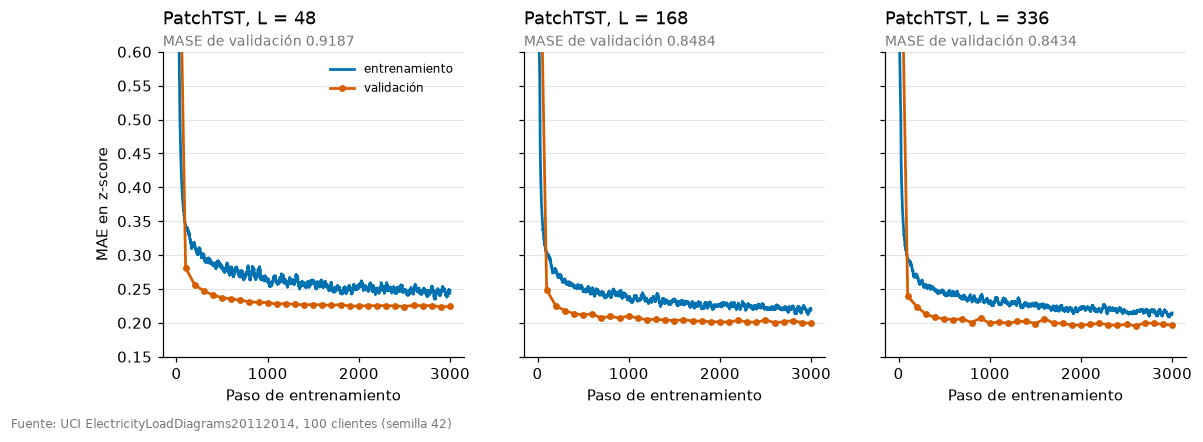

In [7]:
ids = ["nf_PatchTST_L48", "nf_PatchTST", "nf_PatchTST_L336"]
nombres = {"nf_PatchTST_L48": "L = 48", "nf_PatchTST": "L = 168", "nf_PatchTST_L336": "L = 336"}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, id_it in zip(axes, ids):
    d = cargar_iteracion(id_it)
    ct, cv = np.array(d["curva_train"]), np.array(d["curva_val"])
    suave = pd.Series(ct[:, 1]).rolling(25, min_periods=1).mean()
    estilo(ax, f"PatchTST, {nombres[id_it]}", f"MASE de validación {d['MASE_val']:.4f}", "Paso de entrenamiento",
           "MAE en z-score" if id_it == ids[0] else None)
    ax.plot(ct[:, 0], suave, color=AZUL, lw=1.8, label="entrenamiento")
    ax.plot(cv[:, 0], cv[:, 1], color=NARANJA, lw=1.8, marker="o", ms=3.5, label="validación")
    ax.set_ylim(0.15, 0.6)
axes[0].legend(frameon=False, fontsize=8)
pie(fig)
guardar(fig, "4_curvas_patchtst_L")
plt.show()

La ventana de entrada importó. Con L = 48 el MASE de validación fue 0.9187, con L = 168 fue 0.8484 y con L = 336 fue 0.8434. De 48 a 168 la mejora es de 7.6%, pero de 168 a 336 es solo de 0.6% y el entrenamiento casi se duplica (271 contra 529 segundos) y la memoria de la GPU pasa de 1.7 a 3.5 GB. Se eligió L = 336 por tener el menor MASE de validación, pero la diferencia con 168 es chica. Una ventana de una semana (168 horas) ya trae casi todo el patrón, y con 48 horas el modelo no alcanza a ver el mismo día de la semana anterior.

Con la historia, 30 meses dio 0.8434, 3 meses dio 0.8583 y 12 meses dio 0.8630. O sea, más historia ayudó, pero 12 meses quedó peor que 3, y como las tres corridas de PatchTST llegaron a su límite de pasos, esa diferencia de 0.005 está dentro del ruido entre corridas (en la sección de semillas se ve que una semilla distinta mueve el MASE de N-HiTS casi 0.03).

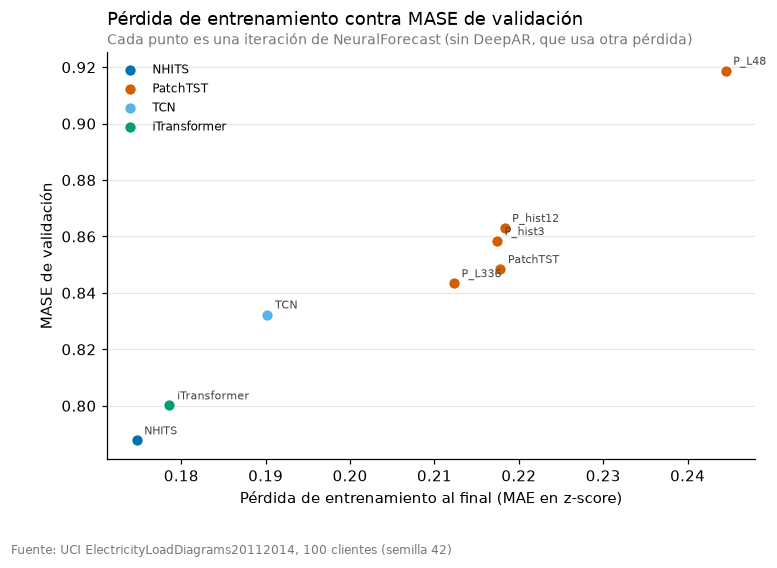

correlación de Spearman entre pérdida de entrenamiento y MASE de validación 0.976


In [8]:
# Una pérdida de entrenamiento más baja no implica un MASE de validación mejor
t = tabla_iteraciones()
t = t[t.modelo != "DeepAR"]
fig, ax = plt.subplots(figsize=(7.6, 4.8))
estilo(ax, "Pérdida de entrenamiento contra MASE de validación", "Cada punto es una iteración de NeuralForecast (sin DeepAR, que usa otra pérdida)",
       "Pérdida de entrenamiento al final (MAE en z-score)", "MASE de validación")
colores = {"NHITS": AZUL, "TCN": "#56B4E9", "iTransformer": VERDE, "PatchTST": NARANJA}
for m, g in t.groupby("modelo"):
    ax.scatter(g["pérdida train final"], g["MASE val"], s=60, color=colores[m], edgecolor="white", label=m, zorder=3)
for _, r in t.iterrows():
    ax.annotate(r["id"].replace("nf_", "").replace("PatchTST_", "P_"), (r["pérdida train final"], r["MASE val"]),
                textcoords="offset points", xytext=(5, 4), fontsize=7, color="#444444")
ax.legend(frameon=False, fontsize=8)
pie(fig)
guardar(fig, "4_perdida_vs_mase")
plt.show()
print("correlación de Spearman entre pérdida de entrenamiento y MASE de validación", round(t[["pérdida train final", "MASE val"]].corr(method="spearman").iloc[0, 1], 3))

En las 8 iteraciones de NeuralForecast de la figura, la pérdida de entrenamiento más baja coincidió con el mejor MASE de validación (correlación de Spearman de 0.98). Eso pasó porque ninguna sobreajustó, y los modelos que aprenden más en entrenamiento también predicen mejor en validación. No se puede generalizar. En los modelos propios del notebook 3 la LSTM con normalización global tuvo la pérdida de entrenamiento más baja de las 18 iteraciones de LSTM (0.050) y también el peor MASE de validación (2.22). Con una sola media y desviación para todos los clientes, la pérdida se mide en otra escala y no se puede comparar con la de las demás configuraciones. Entonces una pérdida de entrenamiento más baja sirve para comparar configuraciones que normalizan igual, pero no siempre implica un mejor MASE.

### 5. Chronos-Bolt zero-shot y pronóstico probabilístico

Chronos-Bolt (`amazon/chronos-bolt-base`, 205 millones de parámetros) no se entrena ni se ajusta. Recibe en kWh las últimas 2,048 horas de cada cliente y devuelve los cuantiles 0.1, 0.5 y 0.9 de las 24 horas siguientes. El P50 es el pronóstico puntual con el que se calculan MAE, RMSE, WAPE y MASE. Solo se mide su tiempo de inferencia.

DeepAR también es probabilístico. Su decodificador recurrente muestrea 100 trayectorias y de ahí salen la mediana y el intervalo de 80%. Para los dos modelos se reportan la pinball loss promedio de los cuantiles 0.1, 0.5 y 0.9 (en kWh) y la cobertura del intervalo P10 a P90, que debería estar cerca de 80%.

In [9]:
pr = metricas(["Chronos-Bolt", "DeepAR"])
for n in ["Chronos-Bolt", "DeepAR"]:
    m = cargar_metricas(n)
    pr.loc[pr.Modelo == n, "Pinball (kWh)"] = m["pinball"]
    pr.loc[pr.Modelo == n, "Cobertura P10-P90"] = m["cobertura_p10_p90"]
pr.round(4)

,Modelo,L,MASE val,MAE,RMSE,WAPE,MASE,MASE Navidad,Entrenamiento (s),Inferencia (s),Hardware,Pinball (kWh),Cobertura P10-P90
0,Chronos-Bolt,2048,0.7465,33.5322,201.6195,0.0594,0.7446,1.3481,0.0000,49.0315,NVIDIA GeForce RTX 4060 Ti (CUDA),11.6010,0.8001
1,DeepAR,168,1.1090,50.2847,210.5276,0.0891,1.1197,1.7673,118.5584,37.1377,NVIDIA GeForce RTX 4060 Ti (CUDA),17.4337,0.7215


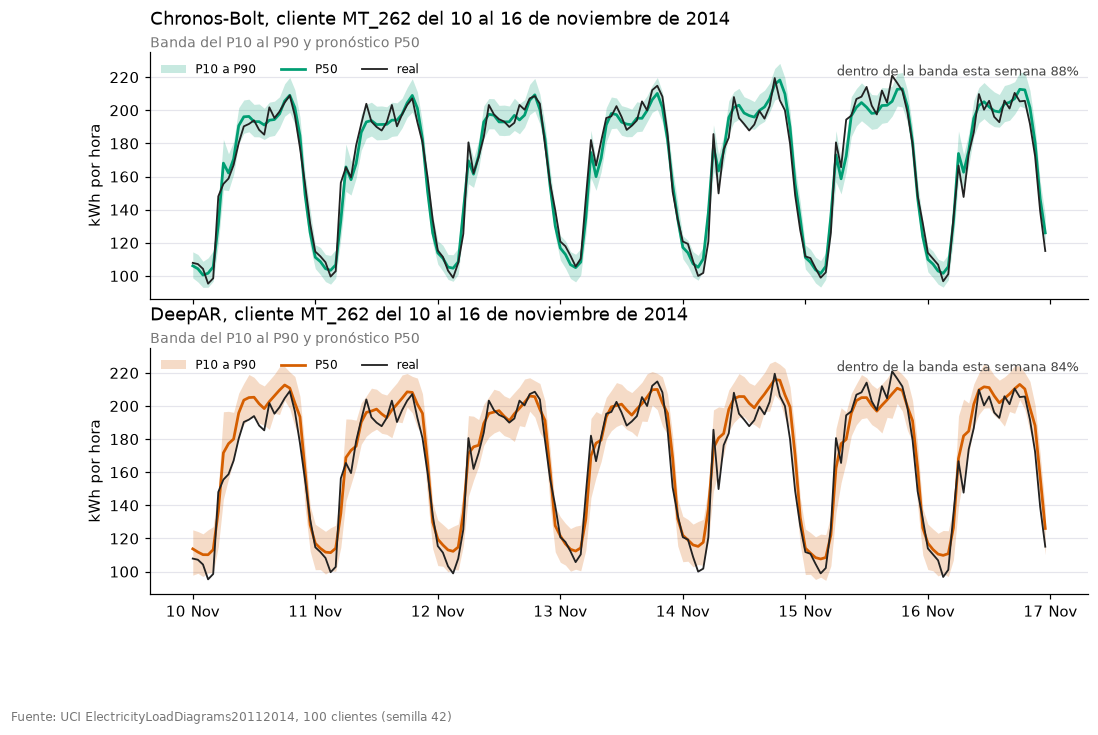

ds,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
Chronos-Bolt,0.834,0.818,0.838,0.844,0.837,0.785,0.832,0.794,0.796,0.800,0.788,0.784,0.783,0.785,0.775,0.772,0.774,0.785,0.787,0.788,0.799,0.823,0.814,0.766
DeepAR,0.880,0.830,0.831,0.815,0.809,0.768,0.817,0.781,0.720,0.728,0.700,0.682,0.667,0.656,0.654,0.638,0.611,0.648,0.660,0.685,0.671,0.683,0.686,0.698


In [10]:
import matplotlib.dates as mdates

pron = {n: pd.read_parquet(R / "pronosticos" / f"{n}.parquet") for n in ["Chronos-Bolt", "DeepAR", "N-HiTS", "SeasonalNaive24"]}
base = pron["Chronos-Bolt"]
media = base.groupby("unique_id").y.mean()
cliente = (media - media.median()).abs().idxmin()
ini, fin = pd.Timestamp("2014-11-10"), pd.Timestamp("2014-11-16 23:00")

fig, axes = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True, sharey=True)
for ax, n, col in zip(axes, ["Chronos-Bolt", "DeepAR"], [VERDE, NARANJA]):
    p = pron[n]
    p = p[(p.unique_id == cliente) & (p.ds >= ini) & (p.ds <= fin)].sort_values("ds")
    estilo(ax, f"{n}, cliente {cliente} del 10 al 16 de noviembre de 2014", "Banda del P10 al P90 y pronóstico P50", None, "kWh por hora")
    ax.fill_between(p.ds, p.q10, p.q90, color=col, alpha=0.22, lw=0, label="P10 a P90")
    ax.plot(p.ds, p.y_hat, color=col, lw=1.8, label="P50")
    ax.plot(p.ds, p.y, color="#222222", lw=1.2, label="real")
    dentro = ((p.y >= p.q10) & (p.y <= p.q90)).mean()
    ax.text(0.99, 0.95, f"dentro de la banda esta semana {dentro:.0%}", transform=ax.transAxes, ha="right", va="top", fontsize=8.5, color="#444444")
    ax.legend(frameon=False, fontsize=8, loc="upper left", ncol=3)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
pie(fig)
guardar(fig, "4_probabilistico")
plt.show()

# cobertura por hora del día
cob = {n: ((p.y >= p.q10) & (p.y <= p.q90)).groupby(p.ds.dt.hour).mean() for n, p in pron.items() if "q10" in p}
pd.DataFrame(cob).round(3).T

Chronos-Bolt quedó con pinball de 11.60 kWh y una cobertura P10 a P90 de 80.0%, justo la que se espera de un intervalo de 80%, o sea que sus cuantiles están bien calibrados. Además su P50 dio el mejor MASE de toda la tabla (0.7446 en prueba y 0.7465 en validación), sin entrenar nada.

DeepAR costó más trabajo. Con la configuración por defecto (distribución StudentT y `h_train = 1`) el MASE de validación fue 6.28, y la pérdida de validación empeoraba desde el inicio. DeepAR se entrena prediciendo un solo paso con el valor real del paso anterior, pero al pronosticar usa sus propias muestras durante 24 pasos, y los errores se acumulan (el mismo efecto del teacher forcing que se explicó en el notebook 2). Con `h_train = 24` mejoró a 1.109 con distribución Normal y a 1.160 con StudentT, y la final fue la de distribución Normal. Aun así su MASE de prueba (1.1197) es peor que el del seasonal naive de 24 horas (1.0337), y su cobertura de 72.2% con pinball de 17.43 kWh muestra que sus intervalos son demasiado angostos. Su pérdida de validación seguía bajando al llegar a los 1,500 pasos permitidos.

### Reentrenamiento mensual

Para el mejor baseline y para el mejor modelo de deep learning se repitió la prueba reentrenando al inicio de cada mes (1 de octubre, 1 de noviembre y 1 de diciembre) con ventana expandible, o sea con todos los datos disponibles hasta ese día. Como en los modelos propios, ya no hay un bloque de validación limpio, entonces el reentrenamiento usa el mismo número de pasos que eligió el early stopping de la corrida original. LightGBM también se reentrenó, porque es un modelo con pesos que sí se pueden actualizar.

In [11]:
from src import comparacion as K
re = K.tabla_reentreno()
re.round(4)

,Modelo,MASE fijo,MASE reentreno mensual,MAE fijo,MAE reentreno mensual,MASE Navidad fijo,MASE Navidad reentreno
0,LightGBM,0.8670,0.8665,38.2738,38.0287,1.6085,1.6377
1,MSTL,0.9228,0.9228,39.7577,39.7577,2.0398,2.0398
2,MLP,0.8194,0.8280,37.3688,37.7750,1.4664,1.4410
3,N-HiTS,0.7844,0.7825,35.5109,35.2636,1.3193,1.3281


El mejor baseline por MASE de validación fue MSTL (0.9013), y como MSTL ya se reajusta en cada uno de los 92 orígenes con las últimas 8 semanas, reentrenar cada mes no cambia nada. El MASE es 0.9228 en los dos casos. Con el seasonal naive pasa igual, porque no tiene parámetros. Por eso también se reentrenó LightGBM, que sí tiene pesos que se pueden actualizar.

Reentrenar casi no cambió el error. En LightGBM el MASE pasó de 0.8670 a 0.8665 y en N-HiTS (el mejor modelo de deep learning) de 0.7844 a 0.7825, o sea una mejora de 0.2% y 0.3%. El MAE de N-HiTS bajó de 35.51 a 35.26 kWh y el RMSE de 174.9 a 171.9. En la semana de Navidad el resultado fue al revés, y el MASE subió de 1.3193 a 1.3281 en N-HiTS y de 1.6085 a 1.6377 en LightGBM. Las mejoras son menores que la diferencia entre semillas (0.017 en N-HiTS), entonces no se pueden distinguir del ruido. Una razón posible es que con 30 meses de historia los modelos ya vieron dos otoños, y agregar uno o dos meses más no les cambia mucho. En cambio el costo sí es real, porque son tres entrenamientos más. Los dos últimos de N-HiTS tardaron 136 y 139 segundos, y el primero tardó 1,530 segundos por una razón que no se investigó.

### Sensibilidad a la semilla del mejor modelo de deep learning

El mejor modelo de deep learning se elige con el MASE de validación entre los modelos propios y los de librería. Se repite con 3 semillas (42, 7 y 123) y se reporta la desviación estándar del MASE.

In [12]:
semillas = [json.loads(p.read_text()) for p in sorted(R.glob("semillas*.json"))]
for s in semillas:
    print(s["modelo"], " MASE de prueba por semilla", [round(c["MASE_prueba"], 4) for c in s["corridas"]],
          " media", round(s["MASE_prueba_media"], 4), " desviación", round(s["MASE_prueba_desv"], 4))

MLP  MASE de prueba por semilla [0.8194, 0.8098, 0.8249]  media 0.8181  desviación 0.0077
N-HiTS  MASE de prueba por semilla [0.7844, 0.784, 0.8131]  media 0.7938  desviación 0.0167


El mejor modelo de deep learning por MASE de validación fue N-HiTS (0.7877), por delante del MLP con RevIN de los modelos propios (0.8041). Con 3 semillas el MASE de prueba fue 0.7844 con la semilla 42, 0.7840 con la 7 y 0.8131 con la 123. La media es 0.7938 y la desviación estándar es 0.0167. La semilla 123 paró por early stopping en el paso 1,899 y dejó un MASE de validación de 0.8698, mientras que las otras dos usaron 2,999 y 2,899 pasos. Casi toda la variación sale de esa corrida. Aun así, su peor semilla (0.8131) le gana al MLP de los modelos propios (0.8194).

Esta desviación es más grande que la diferencia entre N-HiTS e iTransformer en prueba (0.7844 contra 0.7810), entonces no se puede decir que uno sea mejor que el otro. En el MLP del notebook 3 la desviación fue menor, de 0.0077.

### MASE con H = 168

Con un horizonte de una semana se repite la prueba para el seasonal naive de 168 horas y, si da el tiempo, para los modelos de NeuralForecast que se pueden reentrenar con `h = 168`. Con H = 168 solo 86 de los 92 orígenes tienen las 168 horas completas dentro de la prueba, y por eso el MASE no se puede comparar de forma directa con el de H = 24.

In [13]:
h168 = pd.DataFrame([{"Modelo": n, "MASE H=24": cargar_metricas(n)["MASE"], "MASE H=168": cargar_metricas(n).get("MASE_h168"),
                      "Orígenes H=168": cargar_metricas(n).get("n_origenes_h168")}
                     for n in ["SeasonalNaive168", "N-HiTS", "PatchTST", "DLinear", "NLinear", "MLP"]])
h168.round(4)

,Modelo,MASE H=24,MASE H=168,Orígenes H=168
0,SeasonalNaive168,1.1113,1.1197,86
1,N-HiTS,0.7844,0.9948,86
2,PatchTST,0.8764,1.0042,86
3,DLinear,0.8614,0.9872,86
4,NLinear,0.8641,0.9854,86
5,MLP,0.8194,1.0009,86


Con H = 168 todos los modelos probados quedaron cerca de 1. DLinear tuvo 0.9872, NLinear 0.9854, MLP 1.0009, N-HiTS 0.9948 y PatchTST 1.0042, contra 1.1197 del seasonal naive de 168 horas. Los modelos con aprendizaje le ganan al seasonal naive de 168 horas por 10% a 12%. A una semana los modelos lineales quedaron por delante de N-HiTS y de PatchTST, aunque por menos de 2%, y esa diferencia es chica comparada con la variación entre semillas. Se parece a lo que reporta el paper de DLinear para horizontes largos. N-HiTS y PatchTST se reentrenaron con `h = 168` para esta prueba, con los mismos pasos y la misma ventana.